[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/connorharv/byu-cs474/blob/master/lab7_style_transfer.ipynb)

# Style Transfer



In this lab, you will implement the style transfer algorithm proposed by [Gatys et. al. (2015)](https://arxiv.org/pdf/1508.06576.pdf). Your goal is to produce an image that has the high-level content of one image and the low-level style of another.

To perform style transfer, we will use a neural network as a feature extractor to determine style and content features, and we will optimize an image to reach a balance of the chosen style and content. Note that the network does not generate the final image, nor is the network trained at any point in this lab; instead of training network weights, we train the image itself. Through this lab, you will experience another way to use neural networks and see how deep learning can be used to optimize structures other than neural networks.



---

## Grading standards

Your code will be graded on the following:

* 20% Correct extraction of image statistics
* 35% Correct construction of loss function in a loss class
* 20% Plain English description of equations from (Gatys et. al. 2015) at the bottom of the notebook
* 15% Correct initialization and optimization of image variable
* 10% Awesome looking final image

---

Here's an additional example of style transfer:

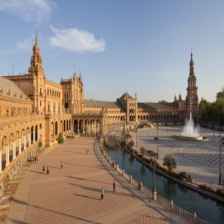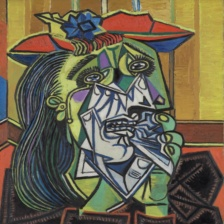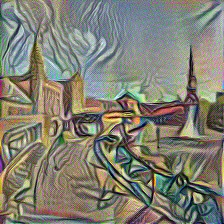

---

## Lab Setup

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from torchvision import transforms
from tqdm import tqdm
from torch.nn.parameter import Parameter
from PIL import Image
import io

# IF NOT USING COLAB: comment out the following import statement:
# from google.colab import files

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Select two images: one for content and one for style. The images should have noticeably different content and style from each other to make it clear if the style transfer worked.

In [2]:
# Use this code to upload your own images.
# NOTE: if you are not using Colab, `upload()` will not work. Just make sure the images are on your file system and set `content_path` and `style_path` accordingly.

load_and_normalize = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
])

#def upload():
#  print('Upload Content Image')
#  file_dict = files.upload()
#  content_path = io.BytesIO(file_dict[next(iter(file_dict))])
#
#  print('\nUpload Style Image')
#  file_dict = files.upload()
#  style_path = io.BytesIO(file_dict[next(iter(file_dict))])
#  return content_path, style_path

import os

content_path, style_path = os.getcwd() + "\\lab7_photos\\content.jpg", os.getcwd() + "\\lab7_photos\\style.jpg"

print("Content Path: {}".format(content_path))
print("Style Path: {}".format(style_path))


Content Path: C:\Users\conbo\PycharmProjects\byu-cs474\lab7_photos\content.jpg
Style Path: C:\Users\conbo\PycharmProjects\byu-cs474\lab7_photos\style.jpg


In [3]:
# Load in and normalize the images
content_image_orig = Image.open(content_path)
content_image = load_and_normalize(content_image_orig).unsqueeze(0).to(device)
style_image_orig = Image.open(style_path)
style_image = load_and_normalize(style_image_orig).unsqueeze(0).to(device)


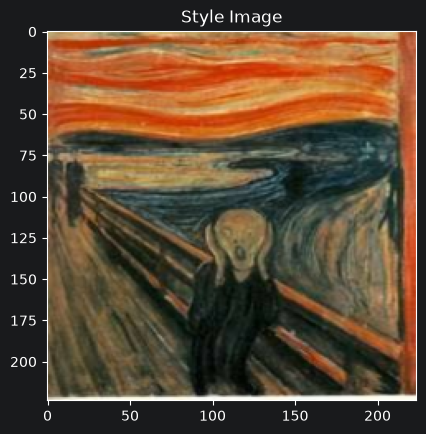

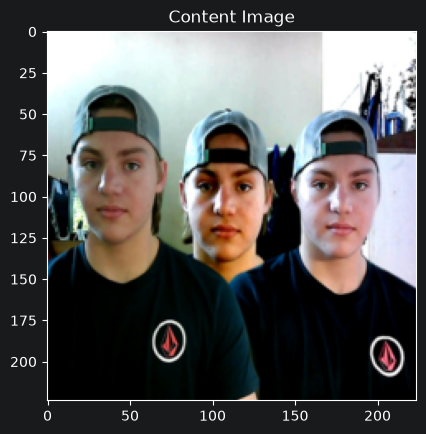

In [4]:
# Display the images
toPIL = transforms.ToPILImage()

def display(tensor, title=None):
    image = tensor.cpu().clone()
    image = image.squeeze(0)
    image = toPIL(image)
    plt.imshow(image)
    if title is not None:
        plt.title(title)
    plt.show()

plt.figure()
display(style_image, title='Style Image')

plt.figure()
display(content_image, title='Content Image')


___

## Part 1


We will use a pretrained VGG-16 network as a feature extractor to get the style and content statistics from the images.

We provide you with the `VGGIntermediate` class to load in the pretrained model and to grab intermediate layers.



* Correctly initialize a VGGIntermediate object to extract style and content
* Gather content statistics from the outputs of intermediate layers for the content image
* Gather style statistics for the style image

In [5]:
import torchvision.models as models

# You should not have to change any of the code in the following classes.

# Normalization layer normalizes the image pixels to mean=0 std=1 according to the statistics of the ImageNet training dataset (which the VGG was pretrained on)
class Normalization(nn.Module):
  def __init__(self):
      super(Normalization, self).__init__()
      self.mean = torch.tensor([0.485, 0.456, 0.406]).view(-1, 1, 1).to(device)
      self.std = torch.tensor([0.229, 0.224, 0.225]).view(-1, 1, 1).to(device)

  def forward(self, img):
      return (img - self.mean) / self.std

# Wrapper for the pretrained VGG-16. Instead of returning the output of the VGG, it returns the `requested` layers.
class VGGIntermediate(nn.Module):
  def __init__(self, requested=[]):
    super(VGGIntermediate, self).__init__()
    self.norm = Normalization().eval()
    self.intermediates = {}
    self.vgg = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1).features.eval()
    for i, m in enumerate(self.vgg.children()):
        if isinstance(m, nn.ReLU):   # we want to set the relu layers to NOT do the relu in place.
          m.inplace = False          # the model has a hard time going backwards on the in place functions.

        if i in requested:
          # This stores the output of the requested layer as `intermediates[i]`
          def curry(i):
            def hook(module, input, output):
              self.intermediates[i] = output
            return hook
          m.register_forward_hook(curry(i))

  def forward(self, x):
    self.vgg(self.norm(x))
    return self.intermediates.copy()

We provide you with the list of VGG-16 layer names. Select the names of the layers you'd like to use to extract the content and style ([Gatys et. al. (2016)](https://arxiv.org/pdf/1508.06576.pdf) has suggestions on which layers to use on pages 3 and 12).

Save the layer indexes (not names) into a list for the `requested` parameter of `VGGIntermediate`.

In [6]:
vgg_names = ["conv1_1", "relu1_1", "conv1_2", "relu1_2", "maxpool1", "conv2_1", "relu2_1", "conv2_2", "relu2_2", "maxpool2", "conv3_1", "relu3_1", "conv3_2", "relu3_2", "conv3_3", "relu3_3","maxpool3", "conv4_1", "relu4_1", "conv4_2", "relu4_2", "conv4_3", "relu4_3","maxpool4", "conv5_1", "relu5_1", "conv5_2", "relu5_2", "conv5_3", "relu5_3","maxpool5"]

In [7]:
requested = [0, 5, 10, 17, 24, 19] # 19 is for CONTENT

Create a `VGGIntermediate` object, providing it with the intermediate layers. You can use a single network to extract both the content and the style, but be sure to keep track of which layers are which.

In [8]:
vggIntermediate = VGGIntermediate(requested).to(device)

Use your `VGGIntermediate` network to extract the content from `content_image` and the style from `style_image`. Save these tensors: they will be used throughout training! Be sure to detach these tensors, since these are our labels and we don't want to backpropagate with respect to them.

In [9]:
content_image_tensor = vggIntermediate(content_image).get(19).detach()
style_image_tensors = vggIntermediate(style_image)

for k in style_image_tensors.keys():
    style_image_tensors[k] = style_image_tensors[k].detach()

---

## Part 2



The loss functions are key to learning the correct behavior in any machine learning problem. For style transfer, we have two losses: content loss and style loss. Our final loss is a combination of both to provide a balance between these competing objectives.

Show that you understand style transfer by describing the key equations of [Gatys et al. 2016](https://arxiv.org/pdf/1508.06576.pdf) in your own words. You may need to read the surrounding sections to understand the equations.

Content Loss:

- Describe equation (1) on p. 10 of (Gatys 2016) in plain English. Include the meaning of all variables and what each dimension represents for each matrix and vector variable.

$\mathcal{L}_{content}(\vec{p}, \vec{x}, l) = \frac{1}{2}\sum_{i,j} (F^l_{ij} - P^l_{ij})^2$

**Your answer here**

It is the sum squared error of the pixel difference between the content image and the generated image by the model.

It sums through all i and j values (filter/channel, pixels) of the image and for each channel-pixel (represented by the subscript `ij`) subtract the original image pixel value `P` from the generated image pixel value `F` at layer `l` in the network (represented by the superscript). This is then squared and summed across all pixels in both images. This is then halved and returned as the content loss.

Style Loss:

- Describe equation (3) on p. 11 of (Gatys 2016) in plain English, including the meaning of all variables and what each dimension represents for each matrix and vector variable (including the output).

$G^l_{ij} = \sum_k F^l_{ik} F^l_{jk}$

**Your answer here**

`G` represents the gram matrix where each element (i for channels, j for flattened pixels) represents the dot product of the feature map `F` at a specific layer (`l` across the pixels).
`k` represents the flattened spatial position (since the 2d image HxW was flattened to 1d).
Each element in `G` is from the dot product of the feature map and its transpose.
It measures the correlation of a particular part of the style image, where a higher value means more of the low-level style has been integrated into the generated picture.


- Describe equation (4) on p. 11 of (Gatys 2016) in plain English, including the meaning of all variables and what each dimension represents for each matrix and vector variable.

$E_l = \frac{1}{4N_l^2M_l^2} \sum_{i,j} (G^l_{ij} - A^l_{ij})^2$

**Your answer here**

It is the normalized sum squared error of the difference between the Gram matrix `G` and the Gram matrix of the original style image `A`.
It is summed across each channel (`i`) and pixel (`j` is the flattened index) at a specific layer `l` in the network. This sum is then normalized and returned as the total loss at a specific layer.


- Describe equation (5) on p. 11 of (Gatys 2016) in plain English, including the meaning of all variables and subscripts.

$\mathcal{L}_{style}(\vec{a}, \vec{x}) = \sum^L_{l=0} w_lE_l$

**Your answer here**

The total style loss of the image (`a` is the original and `x` is the generated) is the sum of each layer `L` of the layer loss `E_l` multiplied by a weighting factor `w`.
The weighing factor is used to weigh each layer's loss (`E_l`) differently, as the initial style loss of the image after being passed through 1 layer of the network should not affect the loss as much as the loss after 5-10 layers through the model.

___

## Part 3


Now that you understand the loss functions mathematically, create modules that calculate the content and style loss for a single content or style layer.

Since the targets will be static throughout learning (the content and style images don't change, nor the network), we can store them in the loss module objects, so we don't have to pass them into the forward each time.

In [10]:
# Produces a gram matrix from a 4D tensor input
def gram_matrix(F):
    b, c, h, w = F.size()
    features = F.view(b, c, h*w)
    G = torch.bmm(features, features.transpose(1, 2))
    return G

# Represents the content loss function for a single content layer
class ContentLoss(nn.Module):
  # Since the targets don't change, store the targets in the init
  def __init__(self, target):
      super().__init__()
      self.target = target

  def forward(self, y_hat):
      return 0.5 * torch.sum((y_hat - self.target)**2)

# Represents the style loss function for a single style layer
class StyleLoss(nn.Module):
  def __init__(self, target):
      super().__init__()
      self.target = target
      self.a_l = gram_matrix(self.target)
      pass

  def forward(self, y_hat):
      # B C H W
      N = self.target.shape[1]
      M = self.target.shape[2] * self.target.shape[3]
      return 1/(4 * N**2 * M**2) * torch.sum((self.a_l - gram_matrix(y_hat)) **2)


# Instantiate a content loss module for each content layer
#  with the content reference image outputs for that layer for comparison
contentLoss = ContentLoss(content_image_tensor).to(device)

# Instantiate a style loss module for each style layer
#  with the style reference image outputs for that layer for comparison
styleLosses = {}
for k, v in style_image_tensors.items():
    styleLosses[k] = StyleLoss(v).to(device)

Now that you have a list of loss modules, write a loss function that computes the combined style transfer loss. You can weight the overall content and style losses, as well as weighting each layerwise loss value.

Return the combined loss as a tensor for learning. Return the content and style loss values for plotting.

In [23]:
alpha = 0.25
beta = 1e8
weights=[4,1,0,0,0,0]

def total_loss(img_dict):
    content_loss = contentLoss(img_dict.get(19))
    style_losses = {}
    for k, v in img_dict.items():
        style_losses[k] = styleLosses[k](v)
    loss_tensor = torch.stack(list(style_losses.values()))
    weight_tensor = torch.tensor(weights, device=device)
    style_loss = torch.sum(loss_tensor * weight_tensor)

    t_loss = (alpha * content_loss) + (beta * style_loss)
    return t_loss, content_loss, style_loss


___

## Part 4

Create and run a method that minimizes the content and style loss for a copy of the content image

Note that the content loss should be zero if you take out the style loss. Why is that?

**TODO:**

* Use an Adam optimizer (try learning rate of .1, but feel free to experiment)
* Show both the content and the style loss every 50 steps
* Ensure that the outputs don't go out of range (clamp them)
* Display the tensor as an image!
* Experiment with different hyperparameters or network layers until you're satisfied with your final image


First, we need to define our image. While we can create a random image and hope that the optimization works, the best results come from using a clone of the content image. That way, the image starts with the desired content and the content loss only needs to preserve the existing content.

Create a clone of the content image as your initial "generated" image. Calculate and print content and style loss (separately) for your generated image. What do you notice about these losses? Make sure the losses match what you'd expect, given that the generated image is a copy of the content image.

In [24]:
generated_image = content_image.detach().clone()

generated_image_dict = vggIntermediate(generated_image)

t_loss, content_loss, style_loss = total_loss(generated_image_dict)

t_loss, content_loss, style_loss

(tensor(1.9482e+12, grad_fn=<AddBackward0>),
 tensor(0., grad_fn=<MulBackward0>),
 tensor(19481.7109, grad_fn=<SumBackward0>))

The content loss matches perfectly since it is exactly the same. The style--since the photos are very different--is extremely high.

Prepare your generated image for optimization. You need two things:


1.   Your generated image must require gradients: set requires_grad to true by setting the object parameter `requires_grad` or calling the function `requires_grad_()`.
2.   Create an optimizer with your generated image as the parameter. Torch optimizers expect a list of parameters (or tensors), so you'll need to wrap your generated image in a single-item list for the optimizer.



In [25]:
# Prepare your generated image to learn
generated_image.requires_grad = True
# Create your optimizer: we suggest starting using an Adam optimizer with lr=.1
adam = torch.optim.Adam([generated_image], lr=0.01)

Now create and run your training loop, storing content and style losses as you train. Remember, you will be optimizing the **generated image** according to the content and style statistics extracted with the network. Print your final image.

For best results, use `torch.clamp_(generated_im.data, 0, 1)` to keep your pixel values in range after each learning step.

Style transfer is very susceptible to overtraining, which introduces a lot of noise to the final image. Print your image often during the training process to find the best-looking image.

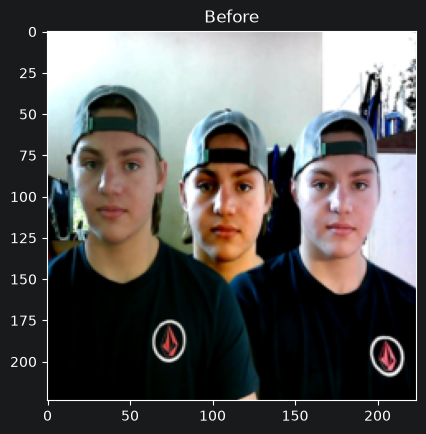

Loss 1948171108352.0 at step 0


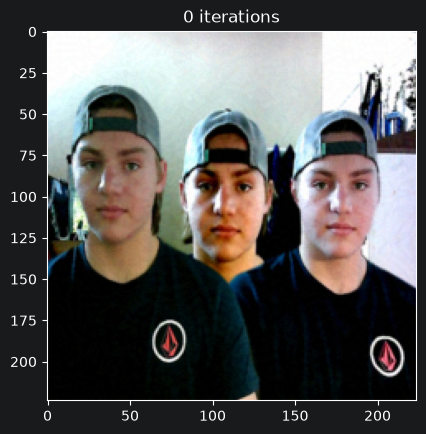

Loss 13449916416.0 at step 100


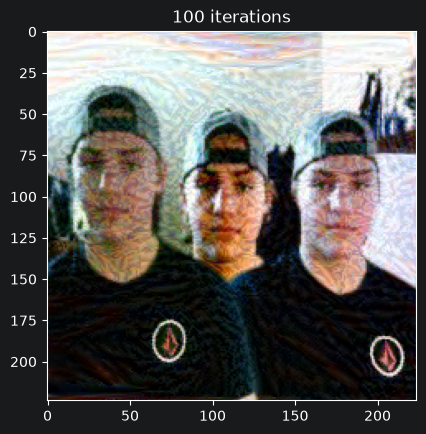

Loss 6515340800.0 at step 200


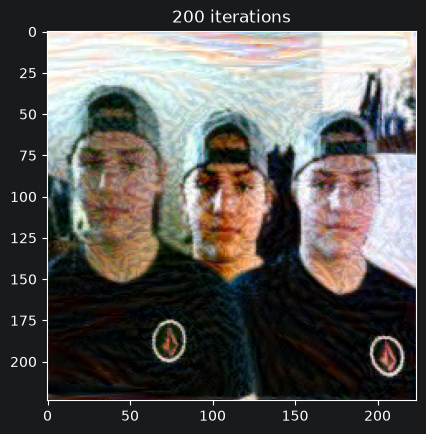

Loss 4272579328.0 at step 300


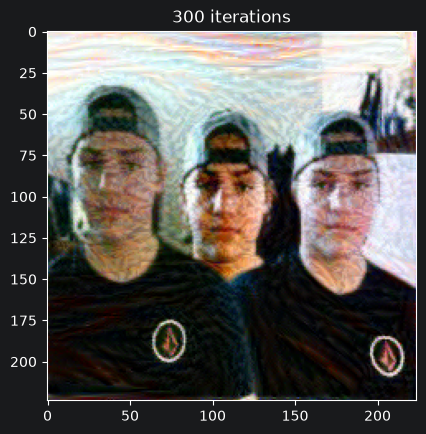

Loss 3179608576.0 at step 400


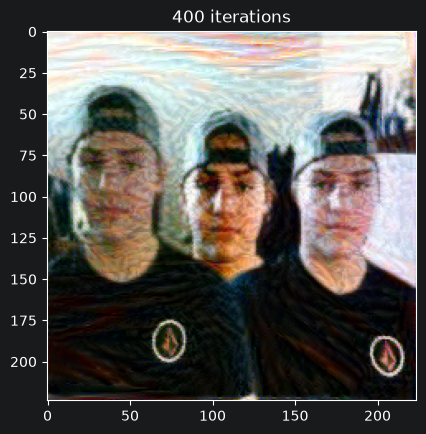

Loss 2555173120.0 at step 500


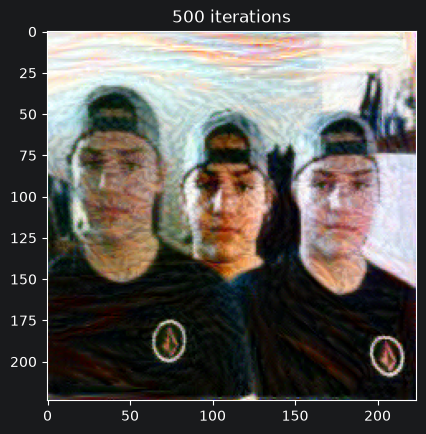

Loss 2151602688.0 at step 600


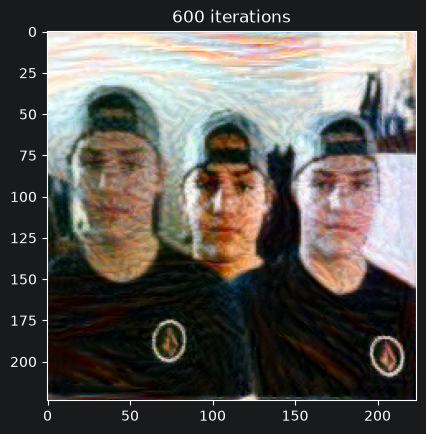

Loss 1867399040.0 at step 700


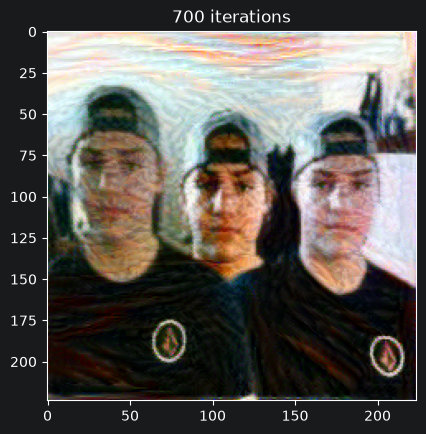

Loss 1657989632.0 at step 800


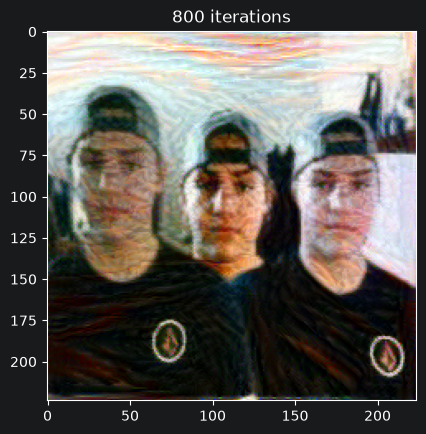

Loss 1495284864.0 at step 900


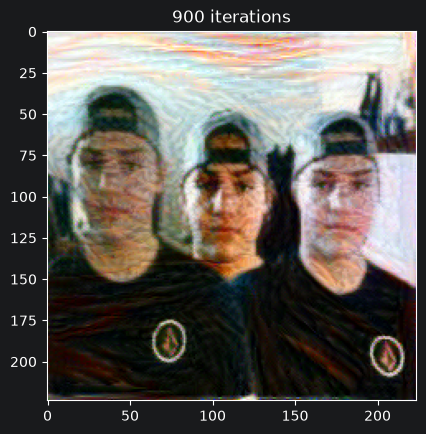

In [26]:

training_steps = 1000

plt.figure()
display(generated_image, title='Before')

for n in range(training_steps):
    adam.zero_grad()

    generated_image_dict = vggIntermediate(generated_image)

    L, content_loss, style_loss = total_loss(generated_image_dict)
    L.backward()
    adam.step()

    generated_image.data.clamp_(0, 1)

    if n % 100 == 0:
        print(f"Loss {L} at step {n}")
        plt.figure()
        display(generated_image, title=f'{n} iterations')


Plot your content and style losses. Content loss should start at 0 and increase as style loss decreases. They should both reach an equilibrium.

Now that you have style transfer working, the results may not look very appealing. Different content and style images require different hyperparameters, so you should play around with different network layers, learning rates, and loss weighting to get the best results.